<a href="https://colab.research.google.com/github/noahgel/Data-Analysis/blob/main/Flipped_Classroom.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1a)

In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
print("Penguins data:")
display(penguins)

print("Missing values per column:")
penguins.isna().sum()
display(penguins.isna().sum())

print("Dropped non-numerical columns:")
penguins_drop = penguins.select_dtypes(include='number')
display(penguins_drop)

print("Removing rows with missing data:")
penguins_2 = penguins.select_dtypes(include='number').dropna()
display(penguins_2)

print("Confirm no missing data in table:")
penguins_2.isna().sum()
display(penguins_2.isna().sum())

Penguins data:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


Missing values per column:


,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


Dropped non-numerical columns:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
3,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0
...,...,...,...,...
339,NaN,NaN,NaN,NaN
340,46.8,14.3,215.0,4850.0
341,50.4,15.7,222.0,5750.0
342,45.2,14.8,212.0,5200.0


Removing rows with missing data:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
4,36.7,19.3,193.0,3450.0
5,39.3,20.6,190.0,3650.0
...,...,...,...,...
338,47.2,13.7,214.0,4925.0
340,46.8,14.3,215.0,4850.0
341,50.4,15.7,222.0,5750.0
342,45.2,14.8,212.0,5200.0


Confirm no missing data in table:


,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0


1b)

In [ ]:
scaler = StandardScaler()
print("Scaled table:")
scaled_array = scaler.fit_transform(penguins_2)
penguins_scaled = pd.DataFrame(scaled_array, columns=penguins_2.columns)
display(penguins_scaled.head())



Scaled table:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,-0.884499,0.785449,-1.418347,-0.564142
1,-0.811126,0.126188,-1.062250,-0.501703
2,-0.664380,0.430462,-0.421277,-1.188532
3,-1.324737,1.089724,-0.563715,-0.938776
4,-0.847812,1.748985,-0.777373,-0.689020


1c)

In [ ]:
import numpy as np

kmean = KMeans(n_clusters=3)
display (kmean)

print("Labels:")
kmeans_labels = kmean.fit_predict(penguins_scaled)
display(kmeans_labels)


KMeans(n_clusters=3)

Labels:


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0,
       2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2,
       2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 0, 2, 2,
       2, 2, 2, 2, 2, 0, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 0, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

1d)

Cluster labels:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,kmeans_labels
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male,0
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female,0
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female,0
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female,0
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male,0


Scatterplot:


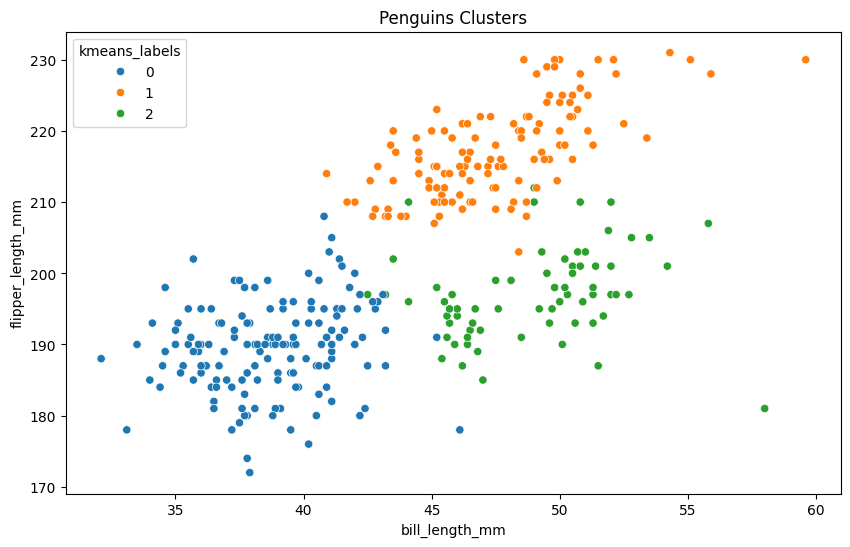

Species Pairplots:


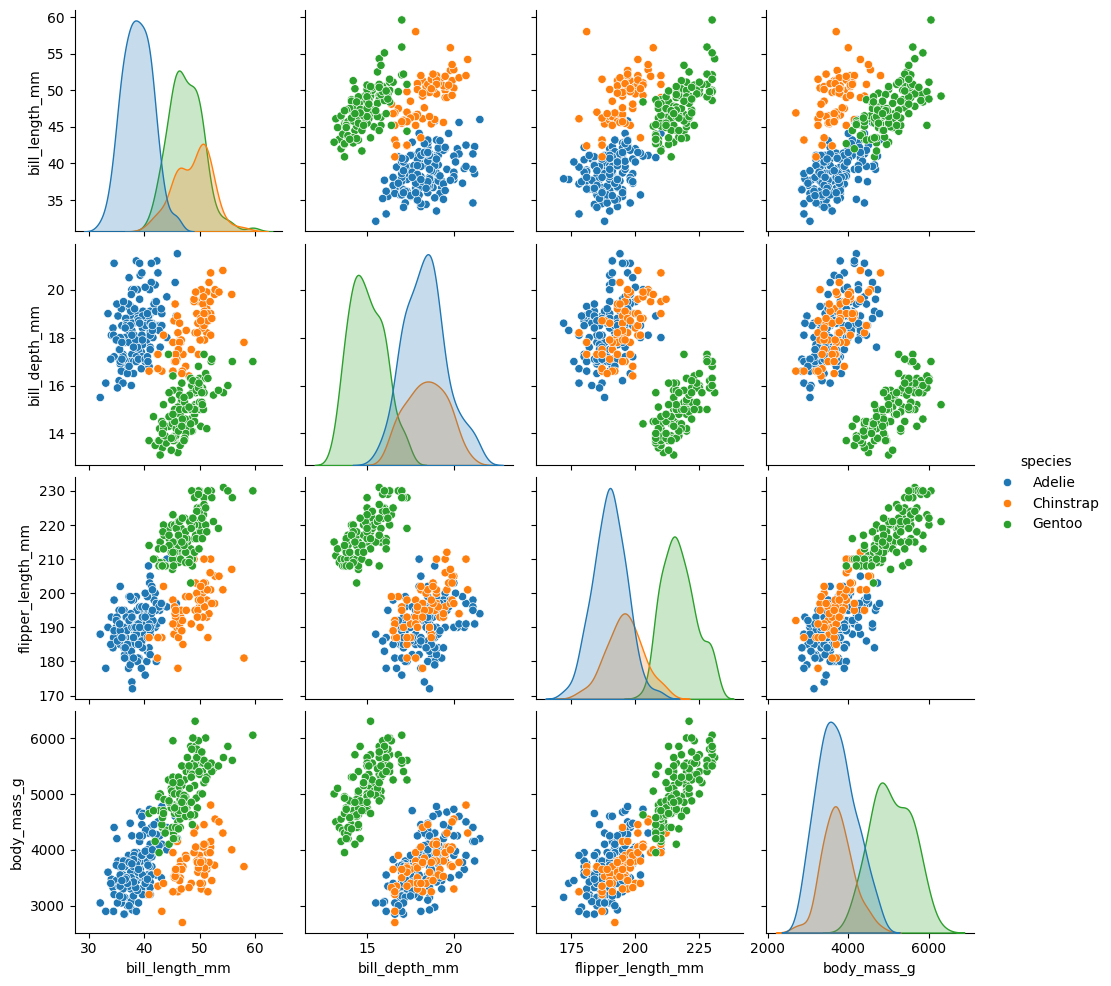

Kmeans Pairplots:


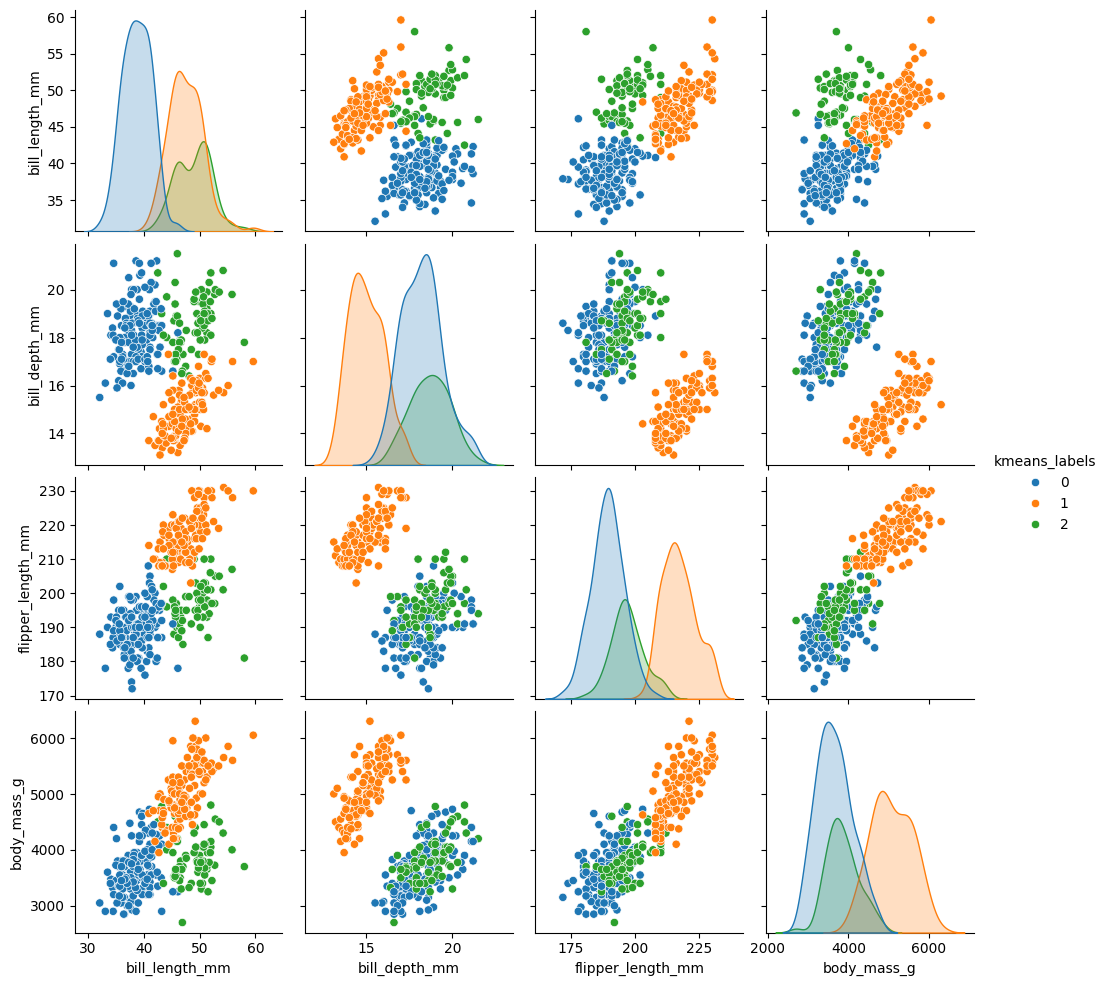

In [ ]:
print("Cluster labels:")
penguins_labeled = penguins.loc[penguins_2.index].copy()
penguins_labeled['kmeans_labels'] = kmeans_labels
penguins_labeled['kmeans_labels'] = penguins_labeled['kmeans_labels'].astype('category')
display(penguins_labeled.head())

print("Scatterplot:")
fig = plt.figure(figsize=(10, 6))
ax = sns.scatterplot(x="bill_length_mm", y="flipper_length_mm",  hue="kmeans_labels", data=penguins_labeled)
ax.set_title('Penguins Clusters')
plt.show()

print("Species Pairplots:")
cols = ['species', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
sns.pairplot(penguins_labeled[cols], hue = 'species')
plt.show()

print("Kmeans Pairplots:")
cols = ['kmeans_labels', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
sns.pairplot(penguins_labeled[cols], hue = 'kmeans_labels')
plt.show()


1e)

1f)

2a)

In [ ]:
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
np.isnan(X).any()

np.False_

2b)

In [ ]:
scaler = StandardScaler()
print("Scaled X Table:")
scaled_array = scaler.fit_transform(X)
X_scaled = pd.DataFrame(scaled_array)
display(X_scaled.head())

Scaled X Table:


,0,1
0,-1.0,-0.233550
1,-1.0,0.700649
2,-1.0,-1.167748
3,1.0,1.634848
4,1.0,0.233550


2c)

In [ ]:
def euclidean_distance(p1,p2):
  total = 0
  for a, b in zip(p1, p2):
    total += (a - b) ** 2
  return total ** 0.5

d_manual = euclidean_distance(X[0], X[3])
d_numpy = np.linalg.norm(X[0] - X[3])

print("Manual:  ", d_manual)
print("np.linalg.norm:", d_numpy)

Manual:   5.656854249492381
np.linalg.norm: 5.656854249492381


2d)

2e)

2f)

2g)

3a)

In [ ]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
print("Original Diamonds Data:")
display(diamonds)

diamonds_num = ['carat', 'depth', 'table', 'price']
diamonds.isna().sum()
print("Missing value check:")
display(diamonds.isna().sum())

print("Removing rows with missing data:")
diamonds_2 = diamonds.select_dtypes(include='number').dropna()
diamonds_2 = diamonds_2.drop(['x', 'y', 'z'], axis=1)
display(diamonds_2)

print("Confirm no missing data in table:")
diamonds_2.isna().sum()
display(diamonds_2.isna().sum())

Original Diamonds Data:


,carat,cut,color,clarity,depth,table,price,x,y,z
1388,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
50052,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
41645,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95
42377,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98
17244,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61
...,...,...,...,...,...,...,...,...,...,...
35207,0.33,Ideal,I,IF,61.6,55.0,891,4.47,4.46,2.75
15806,1.00,Ideal,E,SI1,62.4,55.0,6324,6.34,6.42,3.98
45884,0.58,Ideal,G,VS2,61.1,56.0,1719,5.40,5.43,3.31
22681,0.38,Ideal,J,VVS2,62.0,55.0,629,4.67,4.69,2.90


Missing value check:


,0
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
price,0
x,0
y,0
z,0


Removing rows with missing data:


,carat,depth,table,price
1388,0.24,62.1,56.0,559
50052,0.58,60.0,57.0,2201
41645,0.40,62.1,55.0,1238
42377,0.43,60.8,57.0,1304
17244,1.55,62.3,55.0,6901
...,...,...,...,...
35207,0.33,61.6,55.0,891
15806,1.00,62.4,55.0,6324
45884,0.58,61.1,56.0,1719
22681,0.38,62.0,55.0,629


Confirm no missing data in table:


,0
carat,0
depth,0
table,0
price,0


3b)

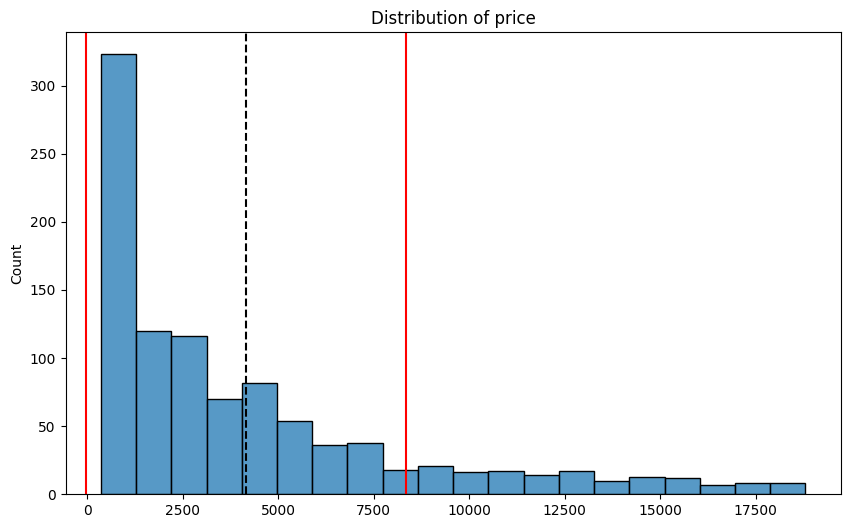

In [ ]:
mean_price = diamonds['price'].mean()
std_price = diamonds['price'].std()

fig = plt.figure(figsize=(10, 6))
ax = sns.histplot(diamonds["price"].values, bins=20)
plt.axvline(mean_price, color="k", linestyle="--")
plt.axvline(mean_price - std_price, color="r", linestyle="-")
plt.axvline(mean_price + std_price, color="r", linestyle="-")
ax.set_title('Distribution of price')
plt.show()

3c)

In [ ]:
scaler = StandardScaler()
print("Diamonds Scaled Table:")
scaled_array = scaler.fit_transform(diamonds_2)
diamonds_scaled = pd.DataFrame(scaled_array, columns=diamonds_2.columns)
display(diamonds_scaled.head())

Diamonds Scaled Table:


,carat,depth,table,price
0,-1.199107,0.242935,-0.594503,-0.861065
1,-0.505156,-1.256222,-0.160179,-0.468993
2,-0.872541,0.242935,-1.028828,-0.698935
3,-0.811310,-0.685115,-0.160179,-0.683176
4,1.474646,0.385712,-1.028828,0.653259


3d)

3e)

3f)

3g)